# 04 · Evaluación en un período nuevo: agosto de 2026

**Proyecto:** Forecast de demanda eléctrica del Mercado Eléctrico Mayorista (MEM) argentino.

## Por qué este notebook

En el notebook 02, el período de test (enero de 2025 → julio de 2026) se usó varias veces: en las revisiones del trabajo se probaron variantes, como la demanda reciente o distintas calibraciones, mirando ese mismo período. Por eso sus resultados ya no son una medición independiente.

Agosto de 2026 no se usó en **ningún** paso del trabajo: la serie versionada termina el 31/07/2026. Es la oportunidad de medir los modelos, ya fijados, sobre datos que nadie miró.

## Protocolo pre-registrado

Este notebook, `src/modelo_demanda.py` y `src/preparar_agosto_2026.py` se guardaron en un commit **antes** de descargar la demanda de agosto (`40e41df`). La desviación de la sección siguiente se documentó en otro commit, también antes de calcular métricas (`9b4612c`). Ese commit fija todo lo que se evalúa:

| Qué | Valor fijado | De dónde sale |
|---|---|---|
| Variables | hora, día de semana, mes, hábil/no hábil, temperatura, promedio de 24 h, grados de calefacción y refrigeración (base 18 °C) | Notebook 02, sección 3 |
| Hiperparámetros del Gradient Boosting | `min_samples_leaf=100`, `max_iter=200`, `max_depth=10`, `learning_rate=0.05`, `l2_regularization=1.0`, `early_stopping=False`, `random_state=42` | Búsqueda con validación temporal (notebook 02, sección 9) |
| Modelo fijo | Entrenado con 2021–2024 (hasta el 30/12/2024 22:00) | Notebook 02, sección 4 |
| Reentrenamiento | Un modelo para todo agosto, entrenado con los últimos 24 meses disponibles al corte del 31/07/2026 a las 11:00 | Validación en 2024 (notebook 02, sección 11.4) |
| Intervalo del 80 % | Cuantiles 10 y 90 con el mismo reentrenamiento, calibración conformal con los puntajes de los últimos 3 meses conocidos al corte | Validación en 2024 (notebook 02, sección 11.5) |
| Variante con demanda reciente | Demanda de hace 48 h y 168 h, modelo fijo entrenado con 2021–2024 | Validación en train (notebook 02, sección 13) |
| Reglas de disponibilidad | Emisión D-1 12:00, corte D-1 11:00, demanda en tiempo real, 12 h de demora para la temperatura histórica y 6 h para las corridas (supuestos) | Notebook 02, sección 4 |
| Temperatura de agosto | Corridas de ECMWF IFS disponibles al corte, igual que en el test | `src/preparar_agosto_2026.py` |

**Qué se reporta:** MAPE, WAPE, RMSE, MAE y sesgo de todos los modelos y referencias; error en horas de demanda alta y en el máximo diario; cobertura, ancho e *interval score* de la banda. Se reportan **aunque empeoren**.

**Reglas:**

- Después de ver los resultados no se cambia ningún parámetro, variable ni regla.
- Si aparece un error de programación que impide ejecutar, se corrige solo ese error y se documenta abajo.
- Se compara con agosto de 2025, un mes ya examinado, para tener una referencia de la misma estación.

**Alcance:** es **un solo mes de invierno**. No valida el desempeño en verano, en olas de calor ni en otras estaciones: confirma, o no, que los resultados del notebook 02 se sostienen en un mes que no se usó.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "processed"
FIG = BASE / "reports" / "figures"
sys.path.insert(0, str(BASE / "src"))
import modelo_demanda as md   # reglas y modelos fijados (mismo código que el notebook 02)

INICIO_NUEVO = pd.Timestamp("2026-08-01")


def guardar(nombre):
    """Muestra el gráfico actual y lo guarda en reports/figures."""
    plt.tight_layout()
    plt.savefig(FIG / f"04_{nombre}.png", bbox_inches="tight")
    plt.show()


print("Hiperparámetros fijados:", md.PARAMS_GB)
print("Ventana de reentrenamiento:", md.VENTANA_MESES, "meses | calibración:", md.CALIBRACION_MESES, "meses")

Hiperparámetros fijados: {'min_samples_leaf': 100, 'max_iter': 200, 'max_depth': 10, 'learning_rate': 0.05, 'l2_regularization': 1.0, 'early_stopping': False, 'random_state': 42}
Ventana de reentrenamiento: 24 meses | calibración: 3 meses


## Desviación del protocolo (documentada antes de calcular métricas)

Al preparar los datos, el control pre-registrado de `src/preparar_agosto_2026.py` se detuvo: la planilla actualizada de CAMMESA no coincide del todo con la serie versionada en el período común.

- **Qué cambió:** solo junio de 2026, en 450 horas de 21 días. La diferencia media es +0,17 % y la máxima, +0,55 %, por encima del umbral pre-registrado de 0,5 %. La media del mes sube 0,11 %. Es el patrón típico de un dato provisorio reemplazado por el definitivo. El tipo de día no cambió, salvo los 4 días ya corregidos.
- **Qué afecta:** junio de 2026 entra en el entrenamiento del modelo reentrenado para agosto (ventana de 24 meses) y en los puntajes de calibración (mayo a julio). **No** afecta a los modelos fijos, entrenados con 2021–2024, ni a la variante con rezagos, porque los rezagos de agosto llegan como mucho a fines de julio.
- **Decisión, tomada antes de ver ningún resultado de agosto:**
  - El **resultado principal** sigue el pre-registro: historial de la serie versionada y agosto de la planilla nueva.
  - Se agrega un **análisis de sensibilidad** que repite el modelo reentrenado y la banda con junio revisado.
  - El control del script ahora guarda las revisiones y se detiene solo si alguna supera el 1 %.
- Esta sección, el análisis de sensibilidad y el cambio del script se guardaron en un commit antes de ejecutar el notebook con los datos de agosto.

## 1. Datos

- Serie versionada (2021 → julio de 2026) con su temperatura histórica, y la temperatura disponible al emitir en el test, igual que en el notebook 02.
- Agosto de 2026: demanda de la planilla actualizada de CAMMESA y temperatura de las corridas disponibles al emitir, preparadas con `src/preparar_agosto_2026.py`.

Agosto no tiene temperatura histórica, y no hace falta: ningún modelo se entrena con agosto, y sus predicciones usan solo la temperatura pronosticada.

In [2]:
serie = pd.read_csv(DATA / "demanda_horaria_mem.csv", parse_dates=["timestamp"])
temperatura = pd.read_csv(DATA / "temperatura_horaria_ba.csv", parse_dates=["timestamp"])
agosto = pd.read_csv(DATA / "demanda_horaria_agosto_2026.csv", parse_dates=["timestamp"])

historia = serie.merge(temperatura, on="timestamp", how="left", validate="one_to_one")
df = pd.concat([historia, agosto[["timestamp", "demanda_mwh", "tipo_dia"]]], ignore_index=True)
df = md.armar_variables(df)   # calendario, clima histórico y rezagos (verifica que la grilla no tenga huecos)

# temperatura disponible al emitir: test (para la calibración) y agosto
pron_test = pd.read_csv(DATA / "temperatura_pronosticada_ba.csv", parse_dates=["timestamp", "dia_objetivo"])
pron_agosto = pd.read_csv(DATA / "temperatura_pronosticada_agosto_2026.csv", parse_dates=["timestamp", "dia_objetivo"])
clima = pd.concat([md.clima_al_emitir(pron_test), md.clima_al_emitir(pron_agosto)])

assert agosto["timestamp"].min() == INICIO_NUEVO and len(agosto) == 744
print(f"Serie completa: {df.timestamp.min()} -> {df.timestamp.max()} ({len(df):,} horas)")
print("Días de agosto con tipo de día corregido por la base diaria:",
      sorted(agosto.loc[agosto["tipo_dia"] != agosto["tipo_dia_planilla"], "timestamp"].dt.date.astype(str).unique()))

Serie completa: 2021-01-01 00:00:00 -> 2026-08-31 23:00:00 (49,656 horas)
Días de agosto con tipo de día corregido por la base diaria: []


## 2. Control: el módulo reproduce el notebook 02

Antes de mirar agosto, se verifica que `src/modelo_demanda.py` dé los mismos resultados que el notebook 02 en el test ya conocido. Si no coincidieran, la evaluación de agosto no estaría midiendo los mismos modelos.

In [3]:
en_train = md.fila_para_entrenar(df["timestamp"], md.FIN_TRAIN)
en_test = (df["timestamp"] >= md.FIN_TRAIN) & (df["timestamp"] < INICIO_NUEVO)
en_agosto = df["timestamp"] >= INICIO_NUEVO


def matriz_al_emitir(mascara, rezagos=False):
    """Variables de las horas seleccionadas, con el clima que se conocía al emitir."""
    t = df.loc[mascara, "timestamp"]
    X = df.loc[mascara, md.VARIABLES].copy()
    X[md.CLIMATICAS] = clima.loc[t.values, md.CLIMATICAS].values
    if rezagos:
        X = X.join(df.loc[mascara, md.REZAGOS])
    return X, t


X_train, y_train = df.loc[en_train, md.VARIABLES], df.loc[en_train, "demanda_mwh"]
modelo_fijo = md.entrenar(X_train, y_train)
con_historia = en_train & df["demanda_hace_168h"].notna()
modelo_rezagos = md.entrenar(df.loc[con_historia, md.VARIABLES + md.REZAGOS], df.loc[con_historia, "demanda_mwh"])

X_test, t_test = matriz_al_emitir(en_test)
y_test = df.loc[en_test, "demanda_mwh"]
reent_test = md.reentrenar_mensual(df, X_test, t_test)
X_test_rez, _ = matriz_al_emitir(en_test, rezagos=True)

control = pd.DataFrame([
    md.evaluar("Gradient Boosting fijo", y_test, modelo_fijo.predict(X_test)),
    md.evaluar("Reentrenado cada mes", y_test, reent_test["pred"]),
    md.evaluar("Con rezagos 48 h y 168 h", y_test, modelo_rezagos.predict(X_test_rez[md.VARIABLES + md.REZAGOS])),
]).set_index("modelo")
# valores del notebook 02 (redondeados a 2 decimales)
esperado = {"Gradient Boosting fijo": 4.08, "Reentrenado cada mes": 4.08, "Con rezagos 48 h y 168 h": 3.61}
for nombre, mape in esperado.items():
    assert round(control.loc[nombre, "MAPE_%"], 2) == mape, f"{nombre}: no reproduce el notebook 02"
print("El módulo reproduce el MAPE del notebook 02 en el test conocido.")
control.round(2)

El módulo reproduce el MAPE del notebook 02 en el test conocido.


,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
modelo,,,,,
Gradient Boosting fijo,4.08,4.21,964.85,689.34,231.65
Reentrenado cada mes,4.08,4.18,934.42,683.67,64.93
Con rezagos 48 h y 168 h,3.61,3.71,872.37,607.02,125.65


## 3. Predicciones de agosto de 2026

Con las reglas fijadas:

- **Modelo fijo** y **variante con rezagos**: los mismos modelos entrenados con 2021–2024.
- **Reentrenado**: un modelo entrenado con lo disponible al corte del 31/07/2026 a las 11:00 (últimos 24 meses), usado para todo agosto.
- **Banda del 80 %**: cuantiles del mismo reentrenamiento, calibrados con los puntajes de mayo a julio de 2026 conocidos al corte.
- **Referencias**: perfil promedio de 2021–2024 y misma hora de la semana anterior.

In [4]:
X_ago, t_ago = matriz_al_emitir(en_agosto)
X_ago_rez, _ = matriz_al_emitir(en_agosto, rezagos=True)
real = pd.Series(df.loc[en_agosto, "demanda_mwh"].values, index=t_ago.values)

# referencias
perfil = df[en_train].groupby(["mes", "hora", "es_habil"])["demanda_mwh"].mean().rename("pred")
pred_perfil = df.loc[en_agosto].join(perfil, on=["mes", "hora", "es_habil"])["pred"].values
pred_semana = df["demanda_mwh"].shift(168)[en_agosto].values

# modelos
pred_fijo = modelo_fijo.predict(X_ago)
reent_ago = md.reentrenar_mensual(df, X_ago, t_ago)
pred_reent = pd.Series(reent_ago["pred"].values, index=t_ago.values)
pred_rez = modelo_rezagos.predict(X_ago_rez[md.VARIABLES + md.REZAGOS])

resultados_agosto = pd.DataFrame([
    md.evaluar("Referencia: perfil promedio", real, pred_perfil),
    md.evaluar("Referencia: misma hora semana anterior", real, pred_semana),
    md.evaluar("Gradient Boosting fijo", real, pred_fijo),
    md.evaluar("Gradient Boosting reentrenado (24 meses)", real, pred_reent),
    md.evaluar("Variante con demanda de hace 48 h y 168 h", real, pred_rez),
]).set_index("modelo")
resultados_agosto.round(2)

,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
modelo,,,,,
Referencia: perfil promedio,7.64,7.89,1587.73,1318.62,897.25
Referencia: misma hora semana anterior,9.28,9.25,1882.80,1545.73,6.96
Gradient Boosting fijo,4.34,4.46,999.99,744.75,605.39
Gradient Boosting reentrenado (24 meses),3.98,4.06,905.97,679.18,435.82
Variante con demanda de hace 48 h y 168 h,3.34,3.41,743.69,569.78,282.87


In [5]:
# banda del 80 %: puntajes de mayo a julio de 2026 (fuera de muestra, con la temperatura disponible al emitir)
previos = (t_test >= INICIO_NUEVO - pd.DateOffset(months=md.CALIBRACION_MESES)).values
puntajes = pd.DataFrame({
    "timestamp": np.concatenate([t_test.values[previos], t_ago.values]),
    "real": np.concatenate([y_test.values[previos], real.values]),
    "q10": np.concatenate([reent_test["q10"].values[previos], reent_ago["q10"].values]),
    "q90": np.concatenate([reent_test["q90"].values[previos], reent_ago["q90"].values]),
})
puntajes["puntaje"] = np.maximum(puntajes["q10"] - puntajes["real"], puntajes["real"] - puntajes["q90"])
ajuste = md.calibrar(puntajes, [INICIO_NUEVO])
es_agosto = (puntajes["timestamp"] >= INICIO_NUEVO).values
inferior = pd.Series((puntajes["q10"] - ajuste)[es_agosto].values, index=t_ago.values)
superior = pd.Series((puntajes["q90"] + ajuste)[es_agosto].values, index=t_ago.values)
print(f"Ajuste conformal de agosto (calculado con puntajes conocidos al 31/07 11:00): {ajuste[es_agosto].iloc[0]:,.0f} MW")

intervalo_agosto = pd.DataFrame([
    md.evaluar_intervalo("Cuantiles 10 y 90, sin calibrar", real,
                         pd.Series(reent_ago["q10"].values, index=t_ago.values), pd.Series(reent_ago["q90"].values, index=t_ago.values)),
    md.evaluar_intervalo("Calibrado (conformal, 3 meses)", real, inferior, superior),
]).set_index("intervalo")
umbral_alta = y_train.quantile(0.90)
picos_agosto = pd.Series(md.evaluar_picos(real, pred_reent, umbral_alta), name="Reentrenado, agosto 2026")
display(intervalo_agosto.round(1))
picos_agosto.round(2)

Ajuste conformal de agosto (calculado con puntajes conocidos al 31/07 11:00): 234 MW


,cobertura_%,ancho_medio_MW,real_arriba_%,real_abajo_%,interval_score_MW,dias_completos_cubiertos_%
intervalo,,,,,,
"Cuantiles 10 y 90, sin calibrar",59.7,1491.6,33.7,6.6,3617.1,12.9
"Calibrado (conformal, 3 meses)",72.4,1959.3,26.1,1.5,3311.1,35.5


horas_demanda_alta             108.00
MAPE_horas_alta_%                5.80
MAPE_maximo_diario_%             4.21
sesgo_maximo_diario_%            3.46
dias_que_subestima_maximo_%     74.19
hora_del_maximo_a_1h_%         100.00
Name: Reentrenado, agosto 2026, dtype: float64

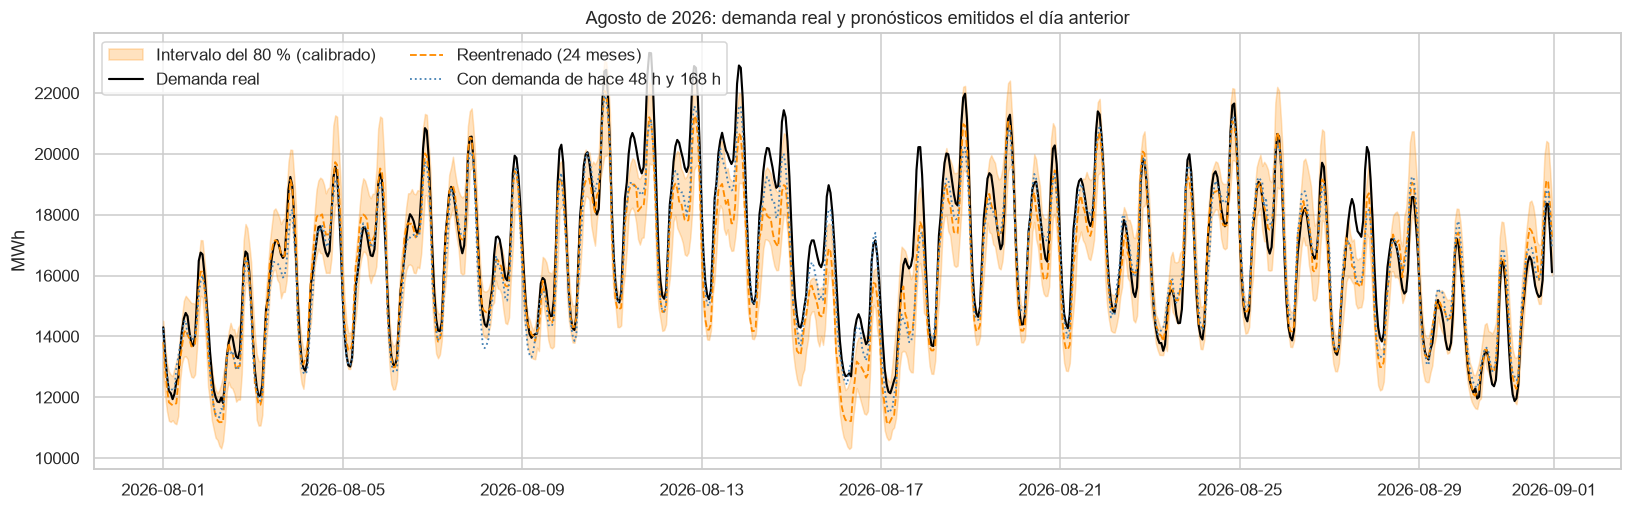

In [6]:
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.fill_between(inferior.index, inferior.values, superior.values, color="darkorange", alpha=0.25, label="Intervalo del 80 % (calibrado)")
ax.plot(real.index, real.values, color="black", lw=1.4, label="Demanda real")
ax.plot(pred_reent.index, pred_reent.values, color="darkorange", ls="--", lw=1.2, label="Reentrenado (24 meses)")
ax.plot(real.index, pred_rez, color="steelblue", ls=":", lw=1.2, label="Con demanda de hace 48 h y 168 h")
ax.set(title="Agosto de 2026: demanda real y pronósticos emitidos el día anterior", ylabel="MWh")
ax.legend(loc="upper left", ncol=2)
guardar("agosto_2026")

### Sensibilidad: junio de 2026 revisado

Se repiten el modelo reentrenado y la banda calibrada reemplazando junio de 2026 por la versión revisada de CAMMESA. El resto queda igual: mismas reglas, mismos parámetros y mismos datos de agosto.

In [7]:
revisiones = pd.read_csv(DATA / "revisiones_cammesa_2026.csv", parse_dates=["timestamp"])
print(f"Horas revisadas: {len(revisiones)} ({revisiones.timestamp.min().date()} -> {revisiones.timestamp.max().date()})")

base_rev = df[["timestamp", "demanda_mwh", "tipo_dia", "temperatura_c"]].copy()
reemplazo = base_rev["timestamp"].map(revisiones.set_index("timestamp")["demanda_revisada"])
base_rev["demanda_mwh"] = reemplazo.fillna(base_rev["demanda_mwh"])
df_rev = md.armar_variables(base_rev)
assert (df_rev["timestamp"].values == df["timestamp"].values).all()

# modelo reentrenado para agosto y puntajes de mayo a julio, con junio revisado
reent_ago_rev = md.reentrenar_mensual(df_rev, X_ago, t_ago)
en_mjj = (t_test >= INICIO_NUEVO - pd.DateOffset(months=md.CALIBRACION_MESES)).values
reent_mjj_rev = md.reentrenar_mensual(df_rev, X_test[en_mjj], t_test[en_mjj])
real_mjj_rev = df_rev.loc[en_test, "demanda_mwh"].values[en_mjj]

puntajes_rev = pd.DataFrame({
    "timestamp": np.concatenate([t_test.values[en_mjj], t_ago.values]),
    "real": np.concatenate([real_mjj_rev, real.values]),
    "q10": np.concatenate([reent_mjj_rev["q10"].values, reent_ago_rev["q10"].values]),
    "q90": np.concatenate([reent_mjj_rev["q90"].values, reent_ago_rev["q90"].values]),
})
puntajes_rev["puntaje"] = np.maximum(puntajes_rev["q10"] - puntajes_rev["real"], puntajes_rev["real"] - puntajes_rev["q90"])
ajuste_rev = md.calibrar(puntajes_rev, [INICIO_NUEVO])
es_ago = (puntajes_rev["timestamp"] >= INICIO_NUEVO).values
inferior_rev = pd.Series((puntajes_rev["q10"] - ajuste_rev)[es_ago].values, index=t_ago.values)
superior_rev = pd.Series((puntajes_rev["q90"] + ajuste_rev)[es_ago].values, index=t_ago.values)

sensibilidad = pd.DataFrame({
    "Historial versionado (principal)": {
        **{k: v for k, v in md.evaluar("", real, pred_reent).items() if k != "modelo"},
        **{k: v for k, v in md.evaluar_intervalo("", real, inferior, superior).items() if k in ("cobertura_%", "ancho_medio_MW", "interval_score_MW")},
    },
    "Junio de 2026 revisado (sensibilidad)": {
        **{k: v for k, v in md.evaluar("", real, reent_ago_rev["pred"]).items() if k != "modelo"},
        **{k: v for k, v in md.evaluar_intervalo("", real, inferior_rev, superior_rev).items() if k in ("cobertura_%", "ancho_medio_MW", "interval_score_MW")},
    },
})
print("Modelo reentrenado y banda calibrada en agosto de 2026")
sensibilidad.round(2)

Horas revisadas: 450 (2026-06-10 -> 2026-06-30)


Modelo reentrenado y banda calibrada en agosto de 2026


,Historial versionado (principal),Junio de 2026 revisado (sensibilidad)
MAPE_%,3.98,3.98
WAPE_%,4.06,4.07
RMSE_MWh,905.97,900.66
MAE_MWh,679.18,679.58
sesgo_MWh,435.82,431.18
cobertura_%,72.45,74.19
ancho_medio_MW,1959.31,2043.73
interval_score_MW,3311.10,3251.09


## 4. Contexto: el mismo mes un año antes

Agosto de 2025 forma parte del test del notebook 02 (ya examinado). Sirve como referencia de la misma estación: ayuda a distinguir si un resultado de agosto de 2026 es propio de ese mes del año o un cambio de desempeño.

In [8]:
es_ago25 = ((t_test >= "2025-08-01") & (t_test < "2025-09-01")).values
real25 = pd.Series(y_test.values[es_ago25], index=t_test.values[es_ago25])
contexto = pd.DataFrame({
    "Agosto 2025 (ya examinado)": {
        "Gradient Boosting fijo": md.evaluar("", real25, modelo_fijo.predict(X_test)[es_ago25])["MAPE_%"],
        "Reentrenado (24 meses)": md.evaluar("", real25, reent_test["pred"].values[es_ago25])["MAPE_%"],
        "Con rezagos 48 h y 168 h": md.evaluar("", real25, modelo_rezagos.predict(X_test_rez[md.VARIABLES + md.REZAGOS])[es_ago25])["MAPE_%"],
    },
    "Test completo ene-2025 → jul-2026 (ya examinado)": control["MAPE_%"].rename(index={"Reentrenado cada mes": "Reentrenado (24 meses)"}),
    "Agosto 2026 (nuevo)": {
        "Gradient Boosting fijo": resultados_agosto.loc["Gradient Boosting fijo", "MAPE_%"],
        "Reentrenado (24 meses)": resultados_agosto.loc["Gradient Boosting reentrenado (24 meses)", "MAPE_%"],
        "Con rezagos 48 h y 168 h": resultados_agosto.loc["Variante con demanda de hace 48 h y 168 h", "MAPE_%"],
    },
})
print("MAPE (%)")
contexto.round(2)

MAPE (%)


,Agosto 2025 (ya examinado),Test completo ene-2025 → jul-2026 (ya examinado),Agosto 2026 (nuevo)
Gradient Boosting fijo,3.21,4.08,4.34
Reentrenado (24 meses),3.24,4.08,3.98
Con rezagos 48 h y 168 h,2.79,3.61,3.34


## 5. Resultados

Se reportan tal como salieron, sin ningún ajuste posterior.

| Modelo | MAPE agosto 2026 | WAPE | Sesgo (MWh) |
|---|---|---|---|
| Referencia: misma hora semana anterior | 9,28 % | 9,25 % | 7 |
| Referencia: perfil promedio | 7,64 % | 7,89 % | 897 |
| Gradient Boosting fijo | 4,34 % | 4,46 % | 605 |
| Gradient Boosting reentrenado (24 meses) | 3,98 % | 4,06 % | 436 |
| Variante con demanda de hace 48 h y 168 h | 3,34 % | 3,41 % | 283 |

**Lo que se confirma:**

- **El orden de los modelos se mantiene** en un mes que no se usó: los modelos de machine learning les ganan con margen a las dos referencias. El reentrenado mejora al fijo y la variante con demanda reciente es la mejor. Es la primera evidencia independiente de esa variante, que en el notebook 02 se había evaluado sobre un test ya explorado.
- **El error está en el rango del test:** el reentrenado da 3,98 % (4,08 % en el test completo) y la variante con rezagos, 3,34 % (3,61 %).
- **La hora del máximo diario** se ubica a una hora o menos de la real todos los días del mes.

**Lo que empeora o falla:**

- **Comparado con el mismo mes del año anterior, el error es más alto:** en agosto de 2025 el reentrenado daba 3,24 % y en agosto de 2026, 3,98 %. Un mes de invierno no es "fácil" por sí mismo.
- **Todos los modelos subestiman.** El reentrenado se queda corto 436 MWh en promedio, y en el 74 % de los días subestima el máximo diario (en promedio, un 3,5 %). Es el mismo problema de nivel visto en 2026 en el notebook 02: el reentrenamiento lo reduce, pero no lo elimina.
- **La banda del 80 % no cumple:** cubre el **72,4 %** de las horas, y la demanda queda por **encima** el 26 % del tiempo y por debajo solo el 1,5 %. La subcobertura viene de la subestimación, no del ancho. Se ve en el gráfico entre el 10 y el 16 de agosto, cuando la demanda real supera la banda varias veces. Es la misma limitación documentada en el notebook 02 (5 de 19 meses por debajo del 75 %), y ahora aparece en un mes nuevo.

**Sensibilidad a la revisión de junio:** usar junio de 2026 revisado casi no cambia nada. El MAPE del reentrenado queda en 3,98 %, y la cobertura de la banda pasa de 72,4 % a 74,2 %. La conclusión no depende de esa revisión.

**Alcance:** es un solo mes de invierno. Confirma que el orden de los modelos y el nivel de error del notebook 02 se sostienen fuera de la muestra explorada. **No** valida el desempeño en verano, en olas de calor ni en otras estaciones, y no alcanza para afirmar que la banda esté bien calibrada: en este mes no lo estuvo. Con más meses nuevos, septiembre en adelante, se podría repetir la misma evaluación sin cambiar ninguna regla.